In [1]:
# Built-in modules
import math

# Imports from Qiskit
from qiskit import QuantumCircuit
from qiskit.circuit.library import grover_operator, MCMTGate, ZGate
from qiskit.visualization import plot_distribution
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Imports from qiskit-ibm-runtime
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler

In [2]:
def grover_oracle(marked_states) :
    if not isinstance (marked_states,list) : 
        marked_states = [marked_states]
    num_qubits = len(marked_states[0])
    qc = QuantumCircuit(num_qubits)
    num_qubits = len(marked_states[0]) 
    for target in marked_states :
        rev_target = target[::-1]
        zero_ind=[ind for ind in range(num_qubits) if rev_target.startswith("0", ind)]
        
        if zero_ind : 
            qc.x(zero_ind)
        qc.compose(MCMTGate(ZGate(),num_qubits-1 , 1),inplace = True)
        if zero_ind:
            qc.x(zero_ind)
    return qc
        

    


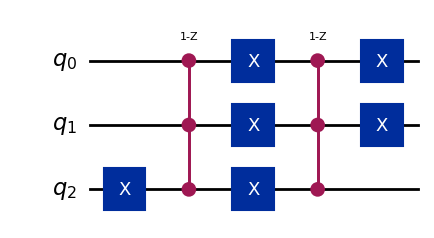

In [3]:
marked_states = ["011", "100"]

oracle = grover_oracle(marked_states)
oracle.draw(output="mpl", style="iqp")

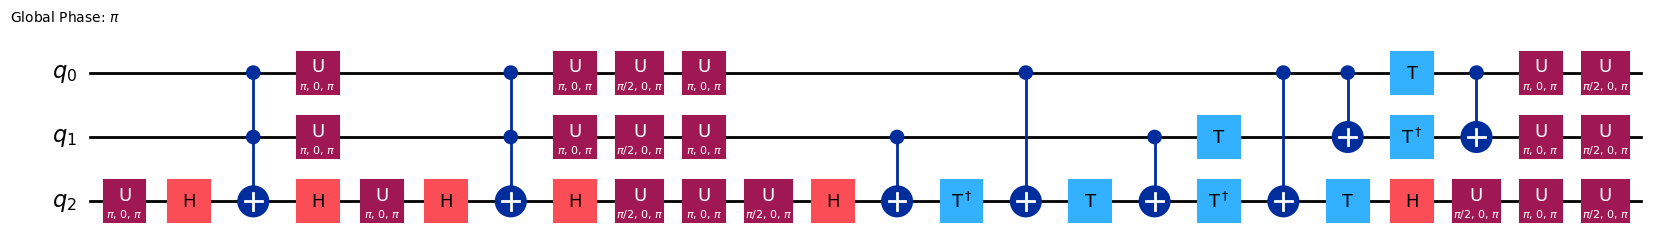

In [4]:
grover_op = grover_operator(oracle)
grover_op.decompose().draw(output="mpl", style="iqp")

In [5]:
optimal_num_iterations = math.floor(
    math.pi
    / (4 * math.asin(math.sqrt(len(marked_states) / 2**grover_op.num_qubits)))
)

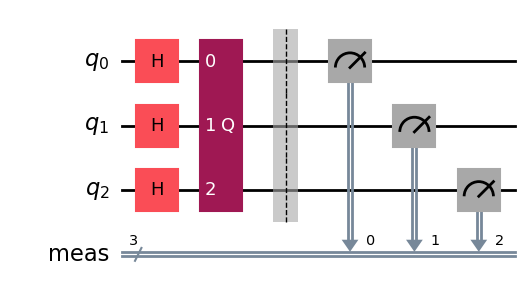

In [6]:
qc = QuantumCircuit(grover_op.num_qubits)
# Create even superposition of all basis states
qc.h(range(grover_op.num_qubits))
# Apply Grover operator the optimal number of times
qc.compose(grover_op.power(optimal_num_iterations), inplace=True)
# Measure all qubits
qc.measure_all()
qc.draw(output="mpl", style="iqp")

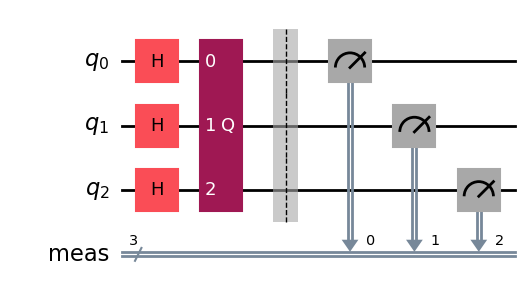

In [7]:
pm = generate_preset_pass_manager(optimization_level=3)
circuit_isa = pm.run(qc)
circuit_isa.draw(output="mpl", idle_wires=False, style="iqp")

In [8]:
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()
result = sampler.run([circuit_isa], shots=10_000).result()
dist = result[0].data.meas.get_counts()

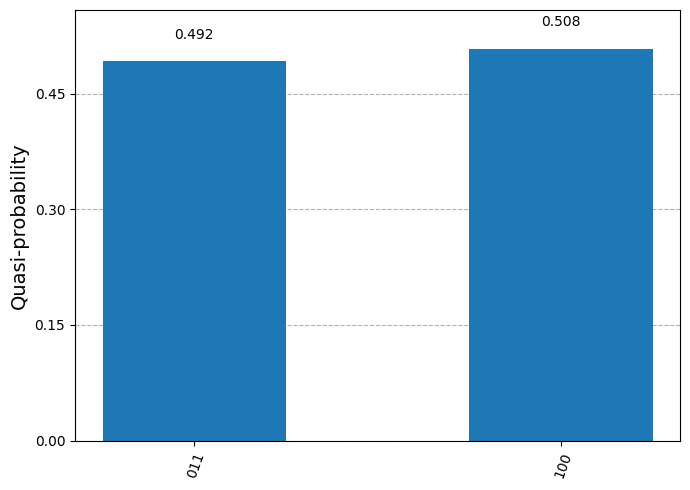

In [9]:
plot_distribution(dist)

In [10]:
from openquantum_sdk.auth import ClientCredentials
from openquantum_sdk.qiskit import OpenQuantumService, SamplerV2, list_backends, get_backend

OpenQuantumService.save_account(
    name="default",
    creds=ClientCredentials(
        client_id="ID",
        client_secret="SECRET",
    ),
)

svc = OpenQuantumService()
print(list_backends(service=svc, device_type="QPU", online=True))

[{'id': '40b5402c-0bfc-493b-9b5d-b7481cbade2c', 'name': 'Garnet', 'description': 'IQM Garnet is a 20-qubit superconducting QPU with high fidelities and tunable couplers.', 'type': 'QPU', 'provider_id': 'fc6b4196-3715-495e-a65f-a80225351f1a', 'short_code': 'iqm:garnet', 'queue_depth': 0, 'accepting_jobs': True, 'status': 'Online'}, {'id': 'c385ea0f-de03-496d-bc21-04a082508fb0', 'name': 'Emerald', 'description': 'IQM Emerald is a 54-qubit superconducting QPU with square lattice connectivity.', 'type': 'QPU', 'provider_id': 'fc6b4196-3715-495e-a65f-a80225351f1a', 'short_code': 'iqm:emerald', 'queue_depth': 0, 'accepting_jobs': True, 'status': 'Online'}, {'id': '4f9ffae1-31a4-46d5-962a-5f3f0f5c757c', 'name': 'IBEX Q1', 'description': 'AQT IBEX Q1 is a 12-qubit trapped-ion quantum processor featuring all-to-all connectivity and high-fidelity operations.', 'type': 'QPU', 'provider_id': '91dd0d6b-6e93-43ad-8cd6-551143aa5c94', 'short_code': 'aqt:ibex-q1', 'queue_depth': 0, 'accepting_jobs': Tr

In [11]:
from qiskit import transpile

BACKEND_ID = "iqm:emerald"
SHOTS = 10_000

backend = get_backend(BACKEND_ID)
print("max shots allowed:", backend.max_shots)
tqc = transpile(
    qc,
    backend=backend,
    initial_layout=[8, 9, 10],
    optimization_level=3,
)
backend.validate_circuit(tqc, shots=SHOTS)
print(tqc.count_ops(), "depth:", tqc.depth())

max shots allowed: 20000
OrderedDict({'cx': 14, 'ry': 13, 't': 9, 'rz': 8, 'x': 7, 'tdg': 6, 'rx': 6, 'h': 5, 'iswap': 4, 'measure': 3, 'swap': 2, 'barrier': 1}) depth: 49


In [ ]:
CONFIG = {
    "backend_class_id": BACKEND_ID,
    "job_subcategory_id": "oth:oth",
    "name": "grover-3qubit-emerald",
    "execution_plan": "auto",
    "queue_priority": "auto",
}

sampler = SamplerV2(
    backend=backend,
    scheduler=svc.scheduler,
    config=CONFIG,
    export_format="qasm3",
)

job = sampler.run([(tqc, None, SHOTS)])
result = job.result()
counts = result[0].data.meas.get_counts()
print(counts)

In [ ]:
from openquantum_sdk.qiskit import OpenQuantumService

svc = OpenQuantumService()
sched = svc.scheduler

job = sched.get_job("")
print("status:", job.status)


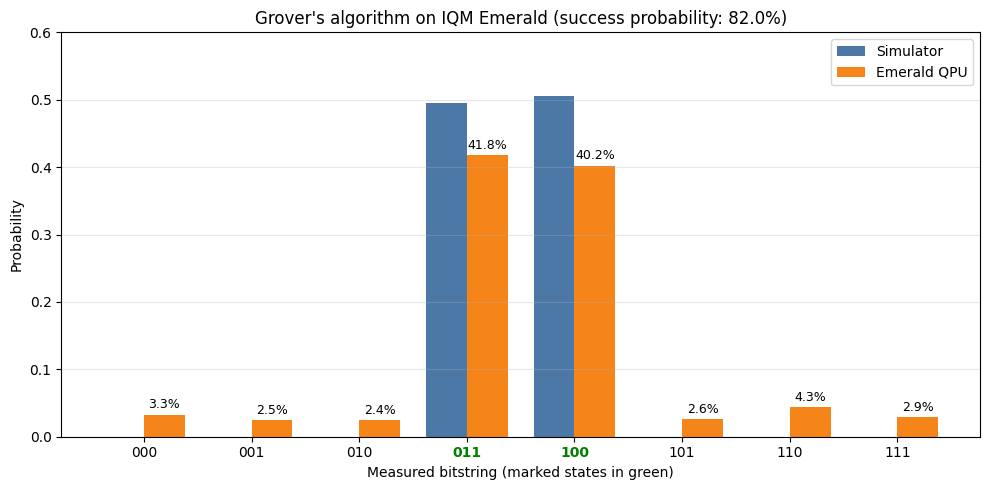

In [22]:
import matplotlib.pyplot as plt
import numpy as np

marked = ["011", "100"]
states = [format(i, "03b") for i in range(8)]          # 000 ... 111

sim_total = sum(dist.values())
hw_total = sum(counts.values())
p_sim = [dist.get(s, 0) / sim_total for s in states]
p_hw = [counts.get(s, 0) / hw_total for s in states]

x = np.arange(len(states))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 5))
bars_sim = ax.bar(x - width/2, p_sim, width, label="Simulator", color="#4c78a8")
bars_hw = ax.bar(x + width/2, p_hw, width, label="Emerald QPU", color="#f58518")

# label each hardware bar with its percentage
for bar, p in zip(bars_hw, p_hw):
    ax.text(bar.get_x() + bar.get_width()/2, p + 0.005, f"{p:.1%}",
            ha="center", va="bottom", fontsize=9)

# bold the marked states on the x axis
ax.set_xticks(x)
ax.set_xticklabels(states)
for tick, s in zip(ax.get_xticklabels(), states):
    if s in marked:
        tick.set_fontweight("bold")
        tick.set_color("green")

p_success = sum(counts.get(s, 0) for s in marked) / hw_total
ax.set_title(f"Grover's algorithm on IQM Emerald (success probability: {p_success:.1%})")
ax.set_xlabel("Measured bitstring (marked states in green)")
ax.set_ylabel("Probability")
ax.set_ylim(0, 0.6)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
import json

with open("json.json") as f:
    out = json.load(f)

print(out)

{'100': 4332, '101': 246, '110': 265, '111': 268, '000': 235, '001': 197, '010': 253, '011': 4204}


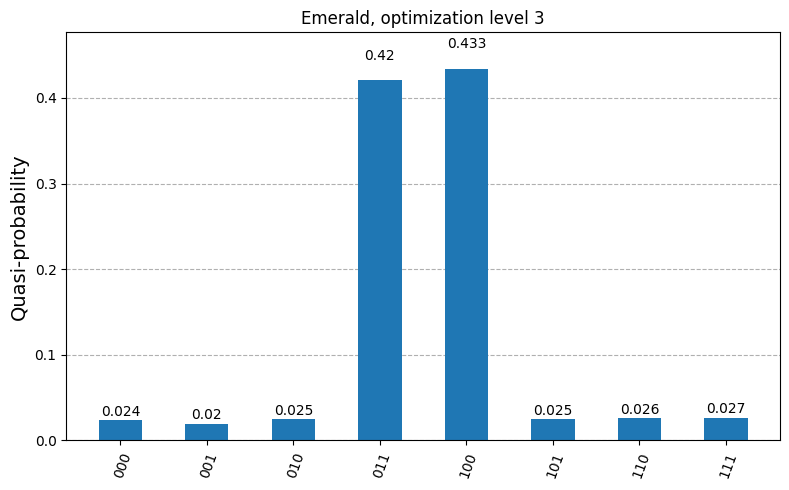

In [14]:
from qiskit.visualization import plot_distribution

plot_distribution(out, title="Emerald, optimization level 3", figsize=(8, 5))